# 03 · Análisis descriptivo — Adopción de IA en empresas (2023–2026)

Este cuaderno responde las **10 preguntas de análisis** con tablas y gráficas, a partir de `datos/derivados/ai_company_adoption_limpio.parquet` (salida de `02_limpieza_ai.ipynb`). Cada pregunta tiene su tabla, su gráfica y una celda "Qué se lee".

**Cómo leerlo**

- **Unidad de análisis:** empresa-trimestre. Se usan las **150.000 filas**, sin promediar por empresa ni fijar un año (registro de decisiones #1 del 02).
- **Asociación no es causalidad.** Las preguntas 4 a 10 describen cómo se mueven juntas dos variables; no dicen que una cause la otra.
- **Las filas de una misma empresa no son independientes.** Hay 10.000 empresas y cada una aparece entre 10 y 16 veces.
- Las escalas de los puntajes (madurez, cumplimiento, satisfacción, etc.) no están documentadas: se comparan entre sí, no se interpretan como porcentajes.
- Los datos están recortados a rangos (hay muchos ceros y topes, ver registro #5 del 02) y no se sabe cómo se generaron. Hay que aclararlo en la ficha del dataset antes de sacar conclusiones "del mundo real".

## 1. Lectura y funciones de apoyo

In [27]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COLOR, DESTACADO = '#4C78A8', '#E45756'

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datos').is_dir())
RUTA = RAIZ / 'datos' / 'derivados' / 'ai_company_adoption_limpio.parquet'
assert RUTA.exists(), f'no se encuentra {RUTA.relative_to(RAIZ)}: correr antes el 02'

df = pd.read_parquet(RUTA)
assert df.shape == (150_000, 43)
print('filas:', len(df), '| empresas:', df['company_id'].nunique(), '| años:', df['survey_year'].min(), 'a', df['survey_year'].max())

filas: 150000 | empresas: 10000 | años: 2023 a 2026


In [28]:
def miles(x):
    return f'{int(x):,}'.replace(',', '.')

# --- Preguntas 1 a 3: promedio por grupo ---------------------------------
def promedio_por_grupo(col, por):
    return (df.groupby(por, observed=True)[col]
              .agg(n='count', media='mean', mediana='median', desvío='std')
              .sort_values('media', ascending=False).round(2))

def media_por_anio(col, por):
    t = df.groupby(['survey_year', por], observed=True)[col].mean().unstack().round(1)
    print('grupo con la media más alta en cada año:', t.idxmax(axis=1).to_dict())
    return t

def barras_horizontales(t, titulo, xlabel):
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(t) + 1.6))
    ax.barh(t.index.astype(str), t['media'], color=[DESTACADO] + [COLOR] * (len(t) - 1))
    ax.invert_yaxis()
    for i, (m, n) in enumerate(zip(t['media'], t['n'])):
        ax.text(m + 0.4, i, f'{m:.1f}  (n = {miles(n)})', va='center', fontsize=9)
    ax.set_xlim(0, t['media'].max() * 1.25)
    ax.set_xlabel(xlabel)
    ax.set_title(titulo, loc='left', fontsize=11)
    plt.tight_layout()
    plt.show()

# --- Preguntas 4, 5, 9 y 10: relación entre dos variables -----------------
def relacion(x, y, xlabel, ylabel, titulo, k=10):
    r = df[x].corr(df[y])
    rho = df[x].corr(df[y], method='spearman')
    print(f'correlación de Pearson: {r:.2f} | de Spearman: {rho:.2f} | n = {miles(len(df))}')
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    hb = ax.hexbin(df[x], df[y], gridsize=45, bins='log', mincnt=1, cmap='Blues')
    tramo = pd.qcut(df[x], k, duplicates='drop')
    g = df.groupby(tramo, observed=True).agg(x=(x, 'mean'), y=(y, 'mean'))
    ax.plot(g['x'], g['y'], color=DESTACADO, marker='o', lw=2, label=f'media por tramo de {k}')
    fig.colorbar(hb, ax=ax, label='filas (escala log)')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{titulo} (r = {r:.2f})', loc='left', fontsize=11)
    ax.legend(loc='upper left', frameon=False)
    plt.tight_layout()
    plt.show()

# --- Tramos por cuantiles o por cortes fijos --------------------------------
def tramos_cuantiles(x, k, decimales=2):
    bordes = df[x].quantile(np.linspace(0, 1, k + 1)).to_numpy()
    etiquetas = [f'{bordes[i]:.{decimales}f} – {bordes[i + 1]:.{decimales}f}' for i in range(k)]
    return pd.cut(df[x], bordes, include_lowest=True, labels=etiquetas)

def resumen_por_tramos(y, tramo):
    return df.groupby(tramo, observed=True)[y].agg(n='count', media='mean', mediana='median').round(2)

def barras_por_tramos(t, xlabel, ylabel, titulo):
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    etiquetas = t.index.astype(str)
    ax.bar(etiquetas, t['media'], color=COLOR, label='media')
    ax.plot(etiquetas, t['mediana'], 'D', color=DESTACADO, label='mediana')
    for i, m in enumerate(t['media']):
        ax.text(i, m, f'{m:.1f}', ha='center', va='bottom', fontsize=9)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(titulo, loc='left', fontsize=11)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

## 2. Panorama de las variables de las preguntas

In [29]:
variables = ['ai_adoption_rate', 'ai_training_hours', 'productivity_change_percent', 'task_automation_rate',
             'time_saved_per_week', 'jobs_displaced', 'ai_budget_percentage', 'revenue_growth_percent',
             'ai_maturity_score', 'cost_reduction_percent', 'ai_risk_management_score',
             'regulatory_compliance_score', 'remote_work_percentage', 'employee_satisfaction_score']
df[variables].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ai_adoption_rate,150000.0,36.41,14.54,0.0,26.43,36.32,46.20,100.00
ai_training_hours,150000.0,27.21,13.14,0.0,18.07,27.06,36.13,80.00
productivity_change_percent,150000.0,9.27,5.64,0.0,5.07,9.06,13.12,34.36
task_automation_rate,150000.0,19.76,9.22,0.0,13.36,19.70,26.02,59.63
time_saved_per_week,150000.0,6.27,2.98,0.0,4.18,6.23,8.29,19.15
jobs_displaced,150000.0,111.37,255.84,0.0,2.00,10.00,41.00,2417.00
ai_budget_percentage,150000.0,9.51,3.84,0.0,6.88,9.43,12.08,25.00
revenue_growth_percent,150000.0,4.61,5.32,-5.0,0.78,4.48,8.24,30.00
ai_maturity_score,150000.0,0.34,0.13,0.0,0.25,0.34,0.44,0.90
cost_reduction_percent,150000.0,4.81,3.38,0.0,2.12,4.62,7.13,20.79


Todas tienen las 150.000 filas completas. Varias tienen medias y medianas parecidas (distribución bastante simétrica), pero `jobs_displaced` es muy asimétrica: media 111, mediana 10 y máximo 2.417. Por eso en la pregunta 6 se muestra también la mediana.

## 3. Preguntas

### P1 · ¿Qué región tiene la mayor tasa promedio de adopción de IA (2023–2026)?

                   n  media  mediana  desvío
region                                      
Oceania        10002  39.40    39.12   14.61
North America   9740  39.15    38.96   14.52
Europe         40835  36.75    36.75   14.45
South America  19909  36.19    36.11   14.42
Asia           49727  36.07    35.98   14.48
Africa         19787  33.95    33.88   14.49


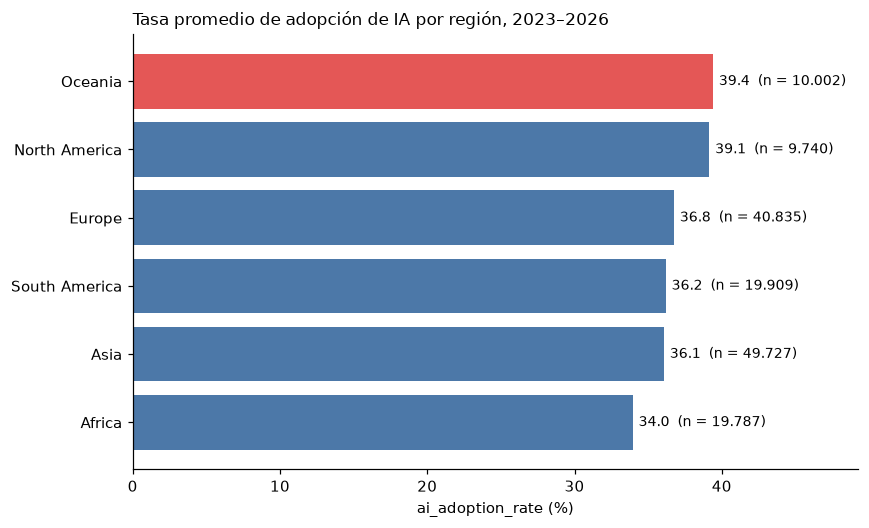


Media por año (para ver si el orden se mantiene):
grupo con la media más alta en cada año: {2023: 'North America', 2024: 'Oceania', 2025: 'Oceania', 2026: 'Oceania'}
region       Africa  Asia  Europe  North America  Oceania  South America
survey_year                                                             
2023           31.0  33.3    33.7           36.2     36.1           33.4
2024           33.0  35.2    35.8           38.2     38.6           35.3
2025           34.9  37.0    37.9           40.1     40.6           37.0
2026           36.8  38.9    39.6           42.0     42.3           39.0


In [30]:
t1 = promedio_por_grupo('ai_adoption_rate', 'region')
print(t1.to_string())
barras_horizontales(t1, 'Tasa promedio de adopción de IA por región, 2023–2026', 'ai_adoption_rate (%)')
print()
print('Media por año (para ver si el orden se mantiene):')
print(media_por_anio('ai_adoption_rate', 'region').to_string())

**Qué se lee.** Oceanía (39,4 %) y Norteamérica (39,2 %) quedan arriba y **prácticamente empatadas**: la diferencia es de 0,25 puntos, con una dispersión de unos 14,5 puntos dentro de cada región. De hecho el liderazgo cambia: Norteamérica en 2023 y Oceanía de 2024 en adelante. Abajo queda África (33,9 %). Todo el rango entre regiones es de unos 5,5 puntos, bastante menos que la dispersión dentro de cada región, así que las regiones se parecen más de lo que se diferencian. La adopción sube cada año en todas (en el total, de 33,5 % en 2023 a 39,2 % en 2026): el orden se mantiene, pero el nivel cambia.

### P2 · ¿Qué sector industrial tiene la mayor tasa promedio de adopción de IA?

                   n  media  mediana  desvío
industry                                    
Technology     21107  42.47    42.43   14.30
Finance        20166  38.35    38.32   14.51
Logistics      12961  35.26    35.07   14.24
Agriculture    15570  35.25    35.19   14.48
Education      15172  35.23    35.16   14.28
Manufacturing  17501  34.73    34.66   14.19
Retail         16377  34.70    34.71   14.22
Healthcare     18642  34.57    34.47   14.07
Consulting     12504  34.52    34.55   14.25


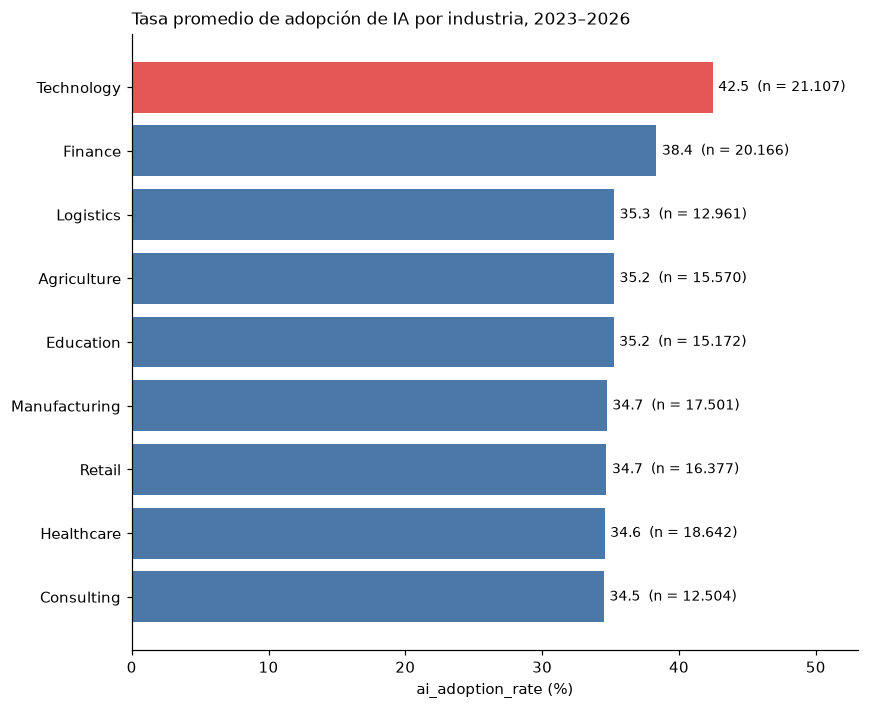


Media por año:
grupo con la media más alta en cada año: {2023: 'Technology', 2024: 'Technology', 2025: 'Technology', 2026: 'Technology'}
industry     Agriculture  Consulting  Education  Finance  Healthcare  Logistics  Manufacturing  Retail  Technology
survey_year                                                                                                       
2023                32.5        31.7       32.3     35.3        31.8       32.6           31.8    31.7        39.3
2024                34.6        33.8       34.0     37.3        33.6       34.2           33.8    33.8        41.8
2025                35.9        35.5       36.4     39.5        35.7       36.1           35.6    35.7        43.6
2026                38.0        37.1       38.2     41.3        37.2       38.2           37.8    37.6        45.2


In [31]:
t2 = promedio_por_grupo('ai_adoption_rate', 'industry')
print(t2.to_string())
barras_horizontales(t2, 'Tasa promedio de adopción de IA por industria, 2023–2026', 'ai_adoption_rate (%)')
print()
print('Media por año:')
print(media_por_anio('ai_adoption_rate', 'industry').to_string())

**Qué se lee.** **Tecnología** lidera con 42,5 %, unos 4 puntos sobre Finanzas (38,3 %), y es la primera en los cuatro años. Las otras siete industrias están todas entre 34,5 % y 35,3 %, casi indistinguibles entre sí. Es decir: hay dos industrias que se separan (Tecnología y, en menor medida, Finanzas) y el resto forma un bloque.

### P3 · ¿Qué tamaño de empresa tiene la mayor adopción de IA?

                  n  media  mediana  desvío
company_size                               
Enterprise    29448  42.83    42.83   14.18
Startup       56685  34.90    34.85   14.26
SME           63867  34.80    34.77   14.14


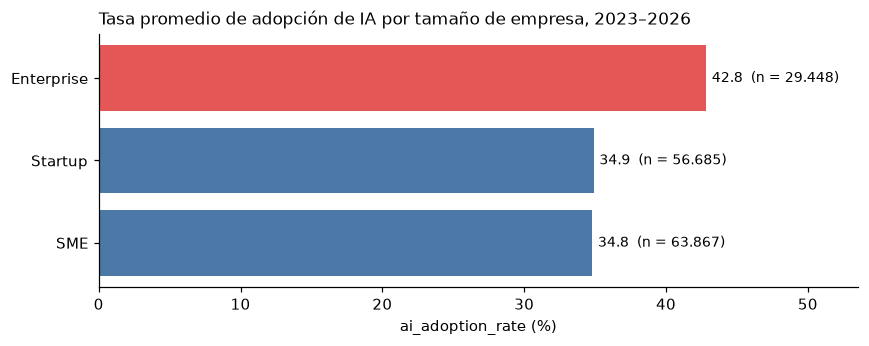


Media por año:
grupo con la media más alta en cada año: {2023: 'Enterprise', 2024: 'Enterprise', 2025: 'Enterprise', 2026: 'Enterprise'}
company_size  Enterprise   SME  Startup
survey_year                            
2023                39.9  31.8     32.1
2024                42.0  33.9     34.0
2025                43.9  35.8     35.9
2026                45.6  37.8     37.6

Mediana de empleados por tamaño:
company_size
Enterprise    10796.0
SME             543.0
Startup          54.0


In [32]:
t3 = promedio_por_grupo('ai_adoption_rate', 'company_size')
print(t3.to_string())
barras_horizontales(t3, 'Tasa promedio de adopción de IA por tamaño de empresa, 2023–2026', 'ai_adoption_rate (%)')
print()
print('Media por año:')
print(media_por_anio('ai_adoption_rate', 'company_size').to_string())
print()
print('Mediana de empleados por tamaño:')
print(df.groupby('company_size', observed=True)['num_employees'].median().to_string())

**Qué se lee.** **Enterprise** lidera con 42,8 %, unos 8 puntos por encima de Startup (34,9 %) y SME (34,8 %), que son prácticamente iguales entre sí. El orden es el mismo en los cuatro años. La diferencia está entre las grandes empresas (mediana de 10.796 empleados) y el resto (543 en las SME y 54 en las startups), no entre pequeñas y medianas.

### P4 · ¿Más horas de capacitación en IA se asocian con mayor cambio de productividad?

correlación de Pearson: 0.63 | de Spearman: 0.62 | n = 150.000


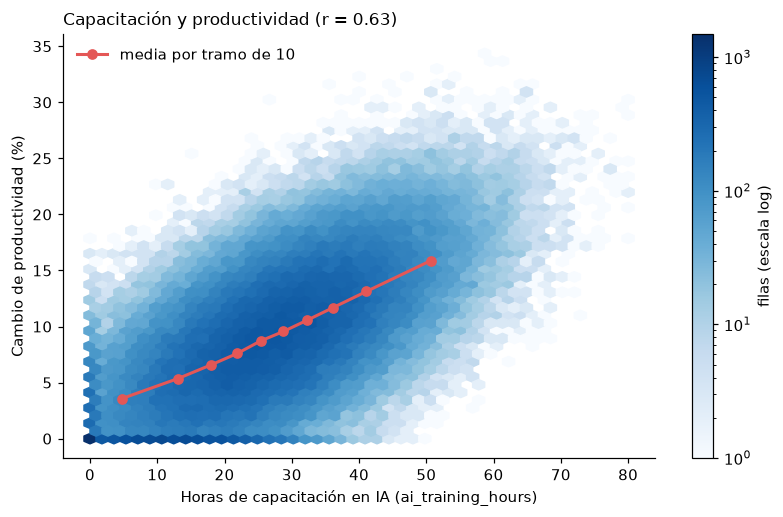


Por quintiles de horas de capacitación:
                       n  media  mediana
ai_training_hours                       
0.0 – 15.8         30014   4.47     3.94
15.8 – 23.7        30025   7.10     6.94
23.7 – 30.5        29961   9.14     9.08
30.5 – 38.4        30025  11.12    11.11
38.4 – 80.0        29975  14.51    14.44


In [33]:
relacion('ai_training_hours', 'productivity_change_percent',
         'Horas de capacitación en IA (ai_training_hours)', 'Cambio de productividad (%)',
         'Capacitación y productividad')
tramo4 = tramos_cuantiles('ai_training_hours', 5, decimales=1)
print()
print('Por quintiles de horas de capacitación:')
print(resumen_por_tramos('productivity_change_percent', tramo4).to_string())

**Qué se lee.** Sí, hay una asociación positiva clara: la correlación es de 0,63. Entre el quinto con menos capacitación y el que más tiene, el cambio promedio de productividad pasa de 4,5 % a 14,5 %, o sea que se triplica, y sube en cada escalón. Es una asociación, no prueba que capacitar cause el aumento. Además 9.027 filas (6 %) tienen productividad exactamente en 0 (es un piso del dato, ver registro #5 del 02).

### P5 · ¿Qué relación hay entre la automatización de tareas y las horas ahorradas por semana?

correlación de Pearson: 0.79 | de Spearman: 0.78 | n = 150.000


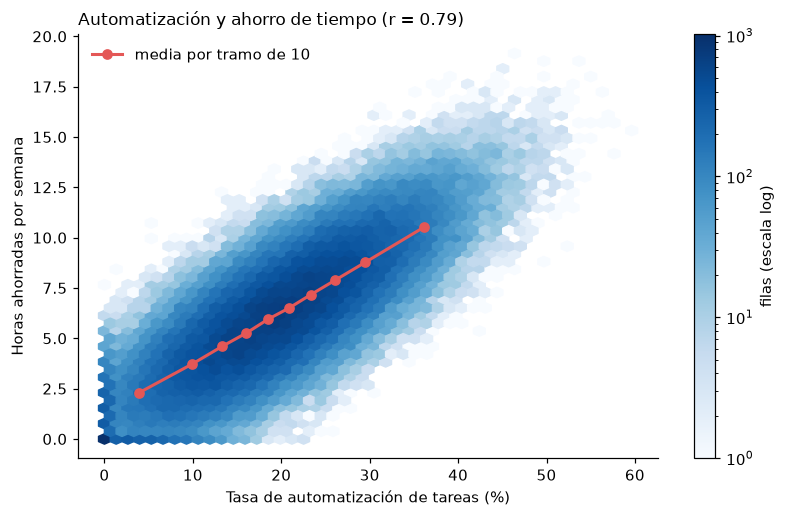


Por quintiles de automatización:
                          n  media  mediana
task_automation_rate                       
0.0 – 11.8            30036   3.01     2.95
11.8 – 17.3           29965   4.94     4.93
17.3 – 22.1           30005   6.23     6.22
22.1 – 27.6           30023   7.52     7.52
27.6 – 59.6           29971   9.65     9.58


In [34]:
relacion('task_automation_rate', 'time_saved_per_week',
         'Tasa de automatización de tareas (%)', 'Horas ahorradas por semana',
         'Automatización y ahorro de tiempo')
tramo5 = tramos_cuantiles('task_automation_rate', 5, decimales=1)
print()
print('Por quintiles de automatización:')
print(resumen_por_tramos('time_saved_per_week', tramo5).to_string())

**Qué se lee.** Es la relación **más fuerte** de las diez preguntas: correlación de 0,79. Entre el quinto con menos automatización y el que más, las horas ahorradas pasan de 3,0 a 9,7 por semana. Que sea tan alta tiene sentido: las dos variables miden cosas muy cercanas (automatizar más tareas libera más tiempo).

### P6 · ¿Las empresas con mayor adopción de IA registran más puestos desplazados?

Se divide la tasa de adopción en **cuatro tramos del mismo tamaño** (cuartiles). Como `jobs_displaced` depende mucho del tamaño de la empresa, se agrega una segunda medida: puestos desplazados **por cada 1.000 empleados**.

                    n  media  mediana  pct_en_0  empleados_mediana  desp_x1000_media
tramo                                                                               
0.00 – 26.43    37506   36.4      4.0      16.2              243.0              25.5
26.43 – 36.32   37503   75.5      9.0       5.2              306.0              37.9
36.32 – 46.20   37496  117.9     15.0       2.1              374.0              47.0
46.20 – 100.00  37495  215.7     29.0       0.5              535.0              60.3

Pearson adopción vs puestos desplazados: 0.28
Spearman adopción vs puestos desplazados: 0.34
Pearson empleados vs puestos desplazados: 0.9


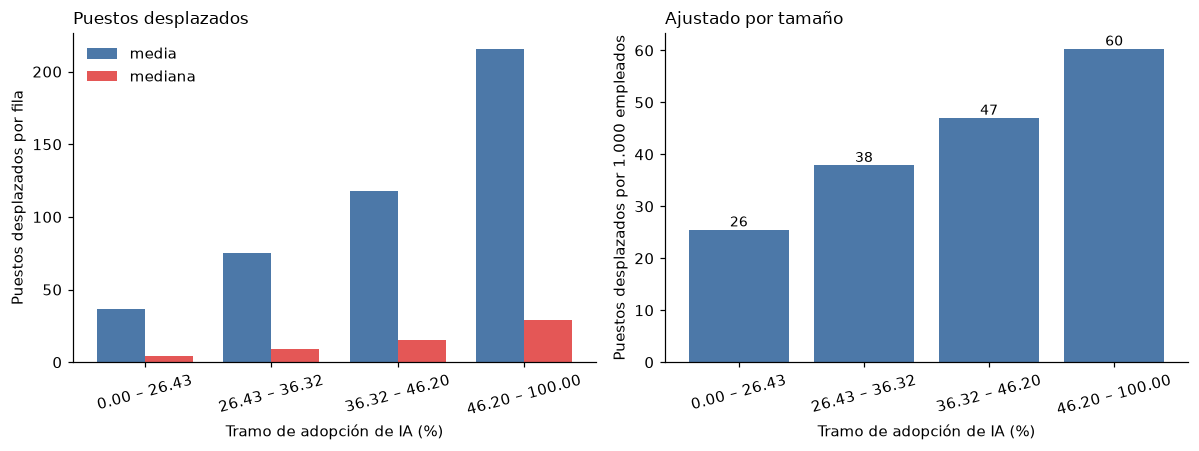

In [35]:
p6 = df[['ai_adoption_rate', 'jobs_displaced', 'num_employees']].copy()
p6['tramo'] = tramos_cuantiles('ai_adoption_rate', 4)
p6['desplazados_x1000'] = p6['jobs_displaced'] / p6['num_employees'] * 1000

t6 = p6.groupby('tramo', observed=True).agg(
    n=('jobs_displaced', 'count'),
    media=('jobs_displaced', 'mean'),
    mediana=('jobs_displaced', 'median'),
    pct_en_0=('jobs_displaced', lambda s: 100 * (s == 0).mean()),
    empleados_mediana=('num_employees', 'median'),
    desp_x1000_media=('desplazados_x1000', 'mean')).round(1)
print(t6.to_string())
print()
print('Pearson adopción vs puestos desplazados:', round(df['ai_adoption_rate'].corr(df['jobs_displaced']), 2))
print('Spearman adopción vs puestos desplazados:', round(df['ai_adoption_rate'].corr(df['jobs_displaced'], method='spearman'), 2))
print('Pearson empleados vs puestos desplazados:', round(df['num_employees'].corr(df['jobs_displaced']), 2))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(len(t6))
w = 0.38
etq = t6.index.astype(str)
ejes[0].bar(x - w / 2, t6['media'], w, color=COLOR, label='media')
ejes[0].bar(x + w / 2, t6['mediana'], w, color=DESTACADO, label='mediana')
ejes[0].set_xticks(x, etq, rotation=15)
ejes[0].set_xlabel('Tramo de adopción de IA (%)')
ejes[0].set_ylabel('Puestos desplazados por fila')
ejes[0].set_title('Puestos desplazados', loc='left', fontsize=11)
ejes[0].legend(frameon=False)
ejes[1].bar(x, t6['desp_x1000_media'], color=COLOR)
for i, v in enumerate(t6['desp_x1000_media']):
    ejes[1].text(i, v, f'{v:.0f}', ha='center', va='bottom', fontsize=9)
ejes[1].set_xticks(x, etq, rotation=15)
ejes[1].set_xlabel('Tramo de adopción de IA (%)')
ejes[1].set_ylabel('Puestos desplazados por 1.000 empleados')
ejes[1].set_title('Ajustado por tamaño', loc='left', fontsize=11)
plt.tight_layout()
plt.show()

**Qué se lee.** Sí: a más adopción, más puestos desplazados. Entre el cuarto de menor adopción y el de mayor, la media pasa de 36 a 216 puestos y la mediana de 4 a 29; además, las filas sin ningún puesto desplazado bajan de 16,2 % a 0,5 %. **Pero buena parte de la diferencia es tamaño:** los puestos desplazados se mueven casi en línea con los empleados (correlación de 0,90) y las empresas con más adopción son más grandes (mediana de 535 empleados contra 243). Al ajustar por tamaño la relación sigue ahí, aunque más moderada: de 26 a 60 puestos por cada 1.000 empleados. No se puede decir que adoptar IA *cause* los desplazamientos.

### P7 · ¿Más presupuesto destinado a IA se asocia con mayor crecimiento de ingresos?

correlación de Pearson: 0.34 | de Spearman: 0.33
                          n  media  mediana
ai_budget_percentage                       
0.00 – 6.88           37585   2.38     2.16
6.88 – 9.43           37467   3.90     3.75
9.43 – 12.08          37449   5.13     5.10
12.08 – 25.00         37499   7.02     7.03


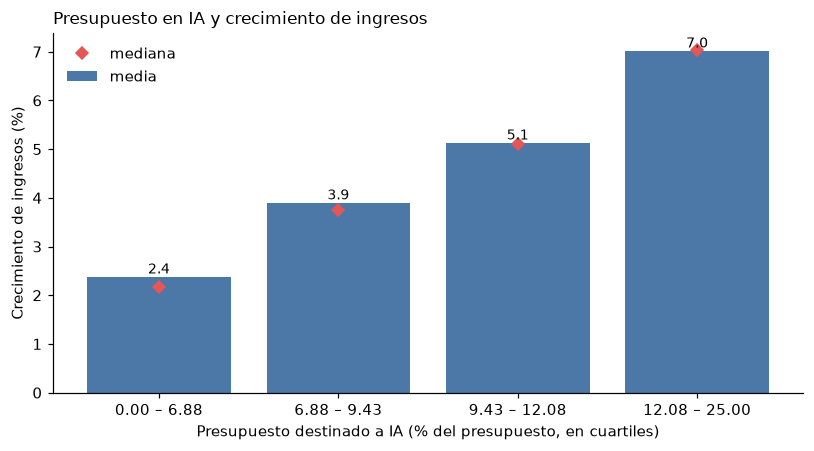

In [36]:
r7 = df['ai_budget_percentage'].corr(df['revenue_growth_percent'])
rho7 = df['ai_budget_percentage'].corr(df['revenue_growth_percent'], method='spearman')
print(f'correlación de Pearson: {r7:.2f} | de Spearman: {rho7:.2f}')
tramo7 = tramos_cuantiles('ai_budget_percentage', 4)
t7 = resumen_por_tramos('revenue_growth_percent', tramo7)
print(t7.to_string())
barras_por_tramos(t7, 'Presupuesto destinado a IA (% del presupuesto, en cuartiles)',
                  'Crecimiento de ingresos (%)', 'Presupuesto en IA y crecimiento de ingresos')

**Qué se lee.** Hay una asociación positiva moderada (correlación de 0,34). El crecimiento promedio de ingresos sube en cada escalón: de 2,4 % en el cuarto con menor presupuesto (hasta 6,9 %) a 7,0 % en el cuarto con mayor presupuesto (más de 12,1 %). El dato de crecimiento tiene un piso en −5 (6.106 filas), y 31.129 filas tienen crecimiento negativo, lo cual es posible y no es un error.

### P8 · ¿Qué nivel de madurez en IA se asocia con mayor reducción de costes?

correlación de Pearson: 0.39 | de Spearman: 0.38
                       n  media  mediana
ai_maturity_score                       
0.00 – 0.25        37685   3.21     2.81
0.25 – 0.34        37379   4.32     4.10
0.34 – 0.43        37641   5.21     5.10
0.43 – 0.90        37295   6.54     6.50


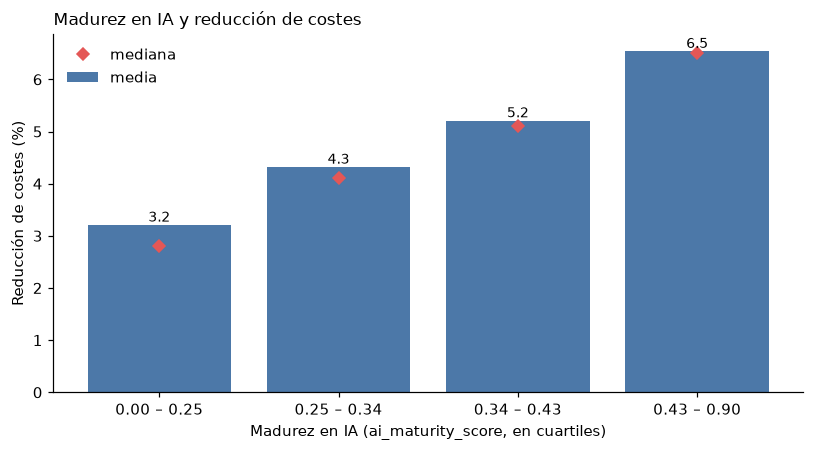

In [37]:
r8 = df['ai_maturity_score'].corr(df['cost_reduction_percent'])
rho8 = df['ai_maturity_score'].corr(df['cost_reduction_percent'], method='spearman')
print(f'correlación de Pearson: {r8:.2f} | de Spearman: {rho8:.2f}')
tramo8 = tramos_cuantiles('ai_maturity_score', 4)
t8 = resumen_por_tramos('cost_reduction_percent', tramo8)
print(t8.to_string())
barras_por_tramos(t8, 'Madurez en IA (ai_maturity_score, en cuartiles)',
                  'Reducción de costes (%)', 'Madurez en IA y reducción de costes')

**Qué se lee.** El nivel de **mayor madurez** (el cuarto superior, aproximadamente 0,44 a 0,90) se asocia con la mayor reducción de costes: 6,5 % en promedio, contra 3,2 % en el cuarto de menor madurez. La correlación es de 0,39 y la reducción sube en cada escalón. Un detalle: el 10,6 % de las filas (15.887) tiene reducción de costes exactamente en 0, un piso del dato que se conservó.

### P9 · ¿Mayor gestión de riesgos de IA se asocia con mayor cumplimiento normativo?

correlación de Pearson: 0.00 | de Spearman: 0.00 | n = 150.000


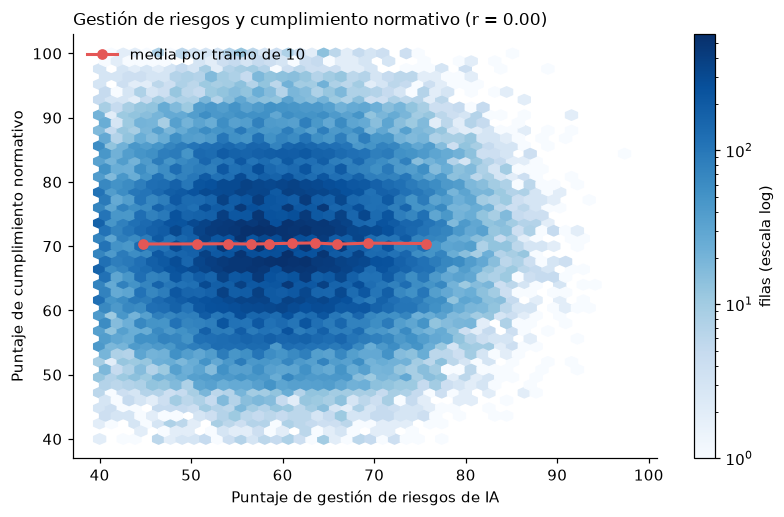


Por quintiles de gestión de riesgos:
                              n  media  mediana
ai_risk_management_score                       
40 – 52                   33063  70.35     70.0
52 – 57                   29537  70.36     70.0
57 – 62                   32219  70.43     70.0
62 – 67                   26727  70.40     70.0
67 – 98                   28454  70.45     70.0


In [38]:
relacion('ai_risk_management_score', 'regulatory_compliance_score',
         'Puntaje de gestión de riesgos de IA', 'Puntaje de cumplimiento normativo',
         'Gestión de riesgos y cumplimiento normativo')
tramo9 = tramos_cuantiles('ai_risk_management_score', 5, decimales=0)
print()
print('Por quintiles de gestión de riesgos:')
print(resumen_por_tramos('regulatory_compliance_score', tramo9).to_string())

**Qué se lee.** **No hay relación**: la correlación es de 0,00 y el cumplimiento normativo promedia casi lo mismo (70,4) en todos los tramos de gestión de riesgos. Las dos puntuaciones, en estos datos, se mueven de forma independiente. Es el único resultado de las diez preguntas que es un "no".

### P10 · ¿Qué relación hay entre el trabajo remoto y la satisfacción de los empleados?

correlación de Pearson: 0.17 | de Spearman: 0.16 | n = 150.000


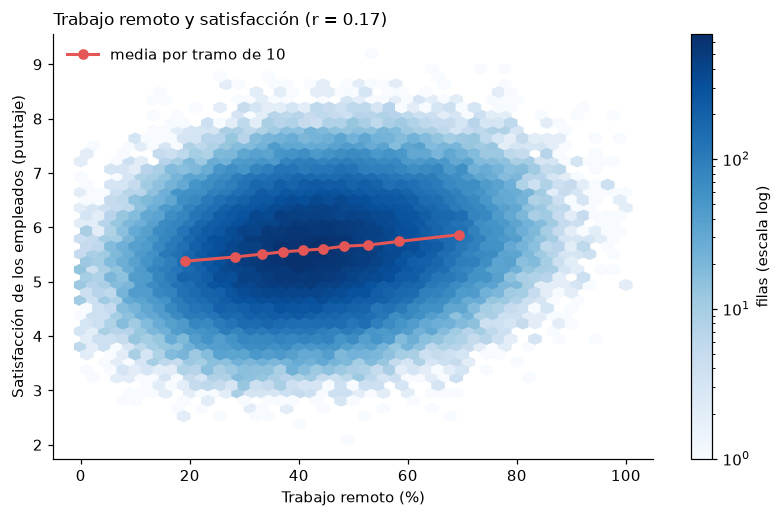


Por tramos de trabajo remoto:
                            n  media  mediana
remote_work_percentage                       
0–20 %                   7067   5.34     5.33
20–40 %                 56903   5.50     5.49
40–60 %                 67116   5.65     5.65
60–80 %                 17928   5.84     5.83
80–100 %                  986   6.00     5.98


In [39]:
relacion('remote_work_percentage', 'employee_satisfaction_score',
         'Trabajo remoto (%)', 'Satisfacción de los empleados (puntaje)',
         'Trabajo remoto y satisfacción')
tramo10 = pd.cut(df['remote_work_percentage'], [0, 20, 40, 60, 80, 100], include_lowest=True,
                 labels=['0–20 %', '20–40 %', '40–60 %', '60–80 %', '80–100 %'])
print()
print('Por tramos de trabajo remoto:')
print(resumen_por_tramos('employee_satisfaction_score', tramo10).to_string())

**Qué se lee.** Hay una asociación positiva **leve** (correlación de 0,17): la satisfacción promedio sube de 5,3 en las empresas con hasta 20 % de trabajo remoto a 6,0 en las de 80 a 100 %. Son menos de 0,7 puntos en una escala cuyo desvío es de 0,8. Ojo con el último tramo: solo tiene 986 filas (0,7 % del total), así que ese valor es el menos firme.

## 4. Resumen de respuestas

| Pregunta | Respuesta corta |
|---|---|
| **P1** · Región | Oceanía y Norteamérica, prácticamente empatadas (39,4 % y 39,2 %); África la más baja (33,9 %) |
| **P2** · Industria | Tecnología (42,5 %), unos 4 puntos sobre Finanzas; las otras siete, entre 34,5 % y 35,3 % |
| **P3** · Tamaño | Enterprise (42,8 %); startups y SME casi iguales (34,9 % y 34,8 %) |
| **P4** · Capacitación y productividad | Asociación positiva clara (r = 0,63): de 4,5 % a 14,5 % de cambio de productividad |
| **P5** · Automatización y ahorro de tiempo | Asociación positiva fuerte (r = 0,79): de 3,0 a 9,7 horas por semana |
| **P6** · Adopción y puestos desplazados | Sí: de 36 a 216 puestos en promedio (de 26 a 60 por 1.000 empleados); buena parte es tamaño de empresa |
| **P7** · Presupuesto y crecimiento de ingresos | Asociación positiva moderada (r = 0,34): de 2,4 % a 7,0 % |
| **P8** · Madurez y reducción de costes | El cuarto de mayor madurez reduce más (6,5 % contra 3,2 %; r = 0,39) |
| **P9** · Riesgos y cumplimiento | Sin relación (r = 0,00): el cumplimiento ronda 70,4 en todos los tramos |
| **P10** · Trabajo remoto y satisfacción | Asociación positiva leve (r = 0,17): de 5,3 a 6,0 puntos |

**Limitaciones.** Son asociaciones, no causas. Las filas de una misma empresa se repiten (10.000 empresas en 150.000 filas). Las escalas de los puntajes no están documentadas. Muchos valores están pegados a pisos y topes. Y no se conoce cómo se generaron los datos ni por qué hay 10.000 saltos en `response_id`.